In [120]:
import os

import SimpleITK as sitk
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import binary_dilation, binary_fill_holes, grey_dilation
from scipy.ndimage import binary_erosion, binary_closing, grey_closing
from scipy.ndimage import binary_opening, gaussian_filter
from skimage.filters import frangi
from skimage.morphology import remove_small_objects

file_name = os.listdir(r"Dataset\DICOMs")[1]
dicom_folder_dir = r"Dataset\DICOMs\\" + file_name
nifit_file_dir = r"Dataset\NIFTIs\\" + file_name + ".nii" + '.gz'

file_name

'002'

In [121]:
dicom_folder_dir, os.listdir(dicom_folder_dir)[:5]

('Dataset\\DICOMs\\\\002',
 ['Image (0001).dcm',
  'Image (0002).dcm',
  'Image (0003).dcm',
  'Image (0004).dcm',
  'Image (0005).dcm'])

In [122]:
# convert entire dicom series to nifti including metadata and compress it
def convert_to_nifti(dicom_dir, nifti_dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dicom_dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    sitk.WriteImage(image, nifti_dir)

# convert_to_nifti(dicom_folder_dir, nifit_file_dir)

In [123]:
_sitk_image = sitk.ReadImage(nifit_file_dir)
_sitk_image.GetSize(), _sitk_image.GetSpacing()

((512, 512, 2000), (0.8066409826278687, 0.8066409826278687, 0.625))

In [135]:
line_points = {
    '001': {
        "z_below_fat": 690,
        "z_above_fat": 980,
        "y_below_fat": 170,
        "seed": [950, 110, 300],
        'vein_slide': 203
    },
    
    '002': {
        "z_below_fat": 840,
        "z_above_fat": 1120,
        "y_below_fat": 252,
        "seed": [1056, 185, 185],
        'vein_slide': 1056 - 840
    },
    
    'HGUCEGXI': {
        "z_below_fat": 175,
        "z_above_fat": 220,
        "y_below_fat": 200,
        "seed": [200, 120, 290],
        'vein_slide': 36
    }
}[file_name]

_seed = line_points['seed']
vein_slide = line_points['vein_slide']

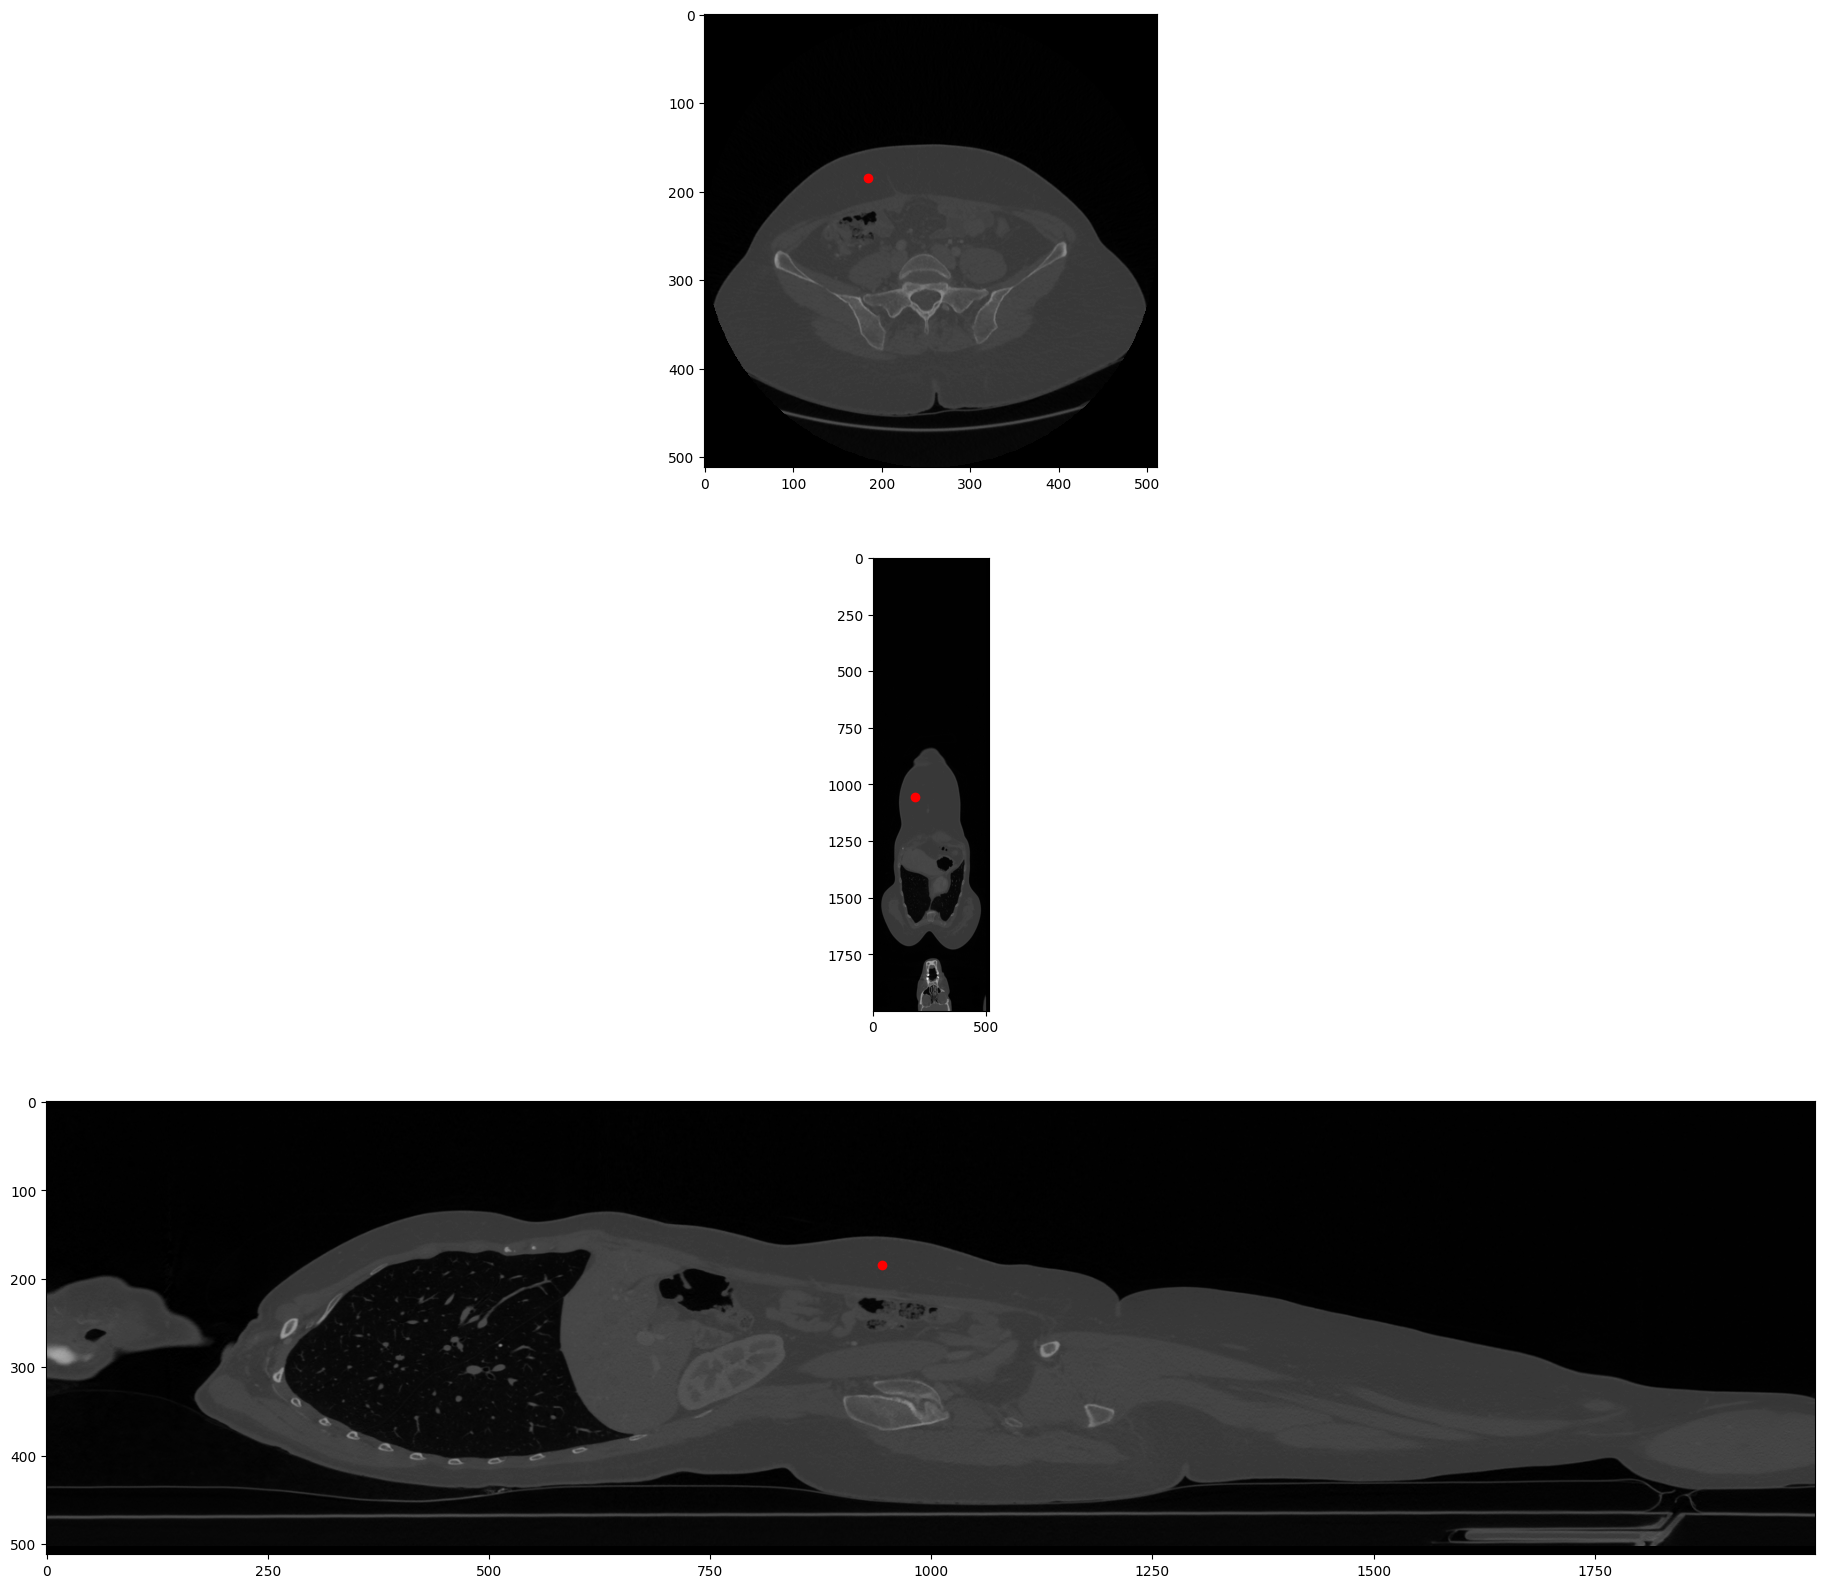

In [125]:
def show_slice(img, mask, seed):
    fig, ax = plt.subplots(3, 1, figsize=(30, 20))
    mask = mask.astype(np.uint8) if mask is not None else None

    ax[0].imshow(img[seed[0], :, :], cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[0].imshow(mask[seed[0], :, :], cmap='Greens', vmin=0, vmax=1, alpha=mask[seed[0], :, :] * 0.5)
    ax[0].scatter(seed[2], seed[1], c='r')

    ax[1].imshow(img[:, seed[1], :], cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[1].imshow(mask[:, seed[1], :], cmap='Greens', vmin=0, vmax=1, alpha=mask[:, seed[1], :] * 0.5)
    ax[1].scatter(seed[2], seed[0], c='r')

    ax[2].imshow(np.rot90(img[:, :, seed[2]], -1), cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[2].imshow(np.rot90(mask[:, :, seed[2]], -1), cmap='Greens', vmin=0, vmax=1,
                     alpha=np.rot90(mask[:, :, seed[2]], -1) * 0.5)
    ax[2].scatter(img.shape[0] - seed[0], seed[1], c='r')

    plt.show()


show_slice(sitk.GetArrayFromImage(_sitk_image), None, _seed)

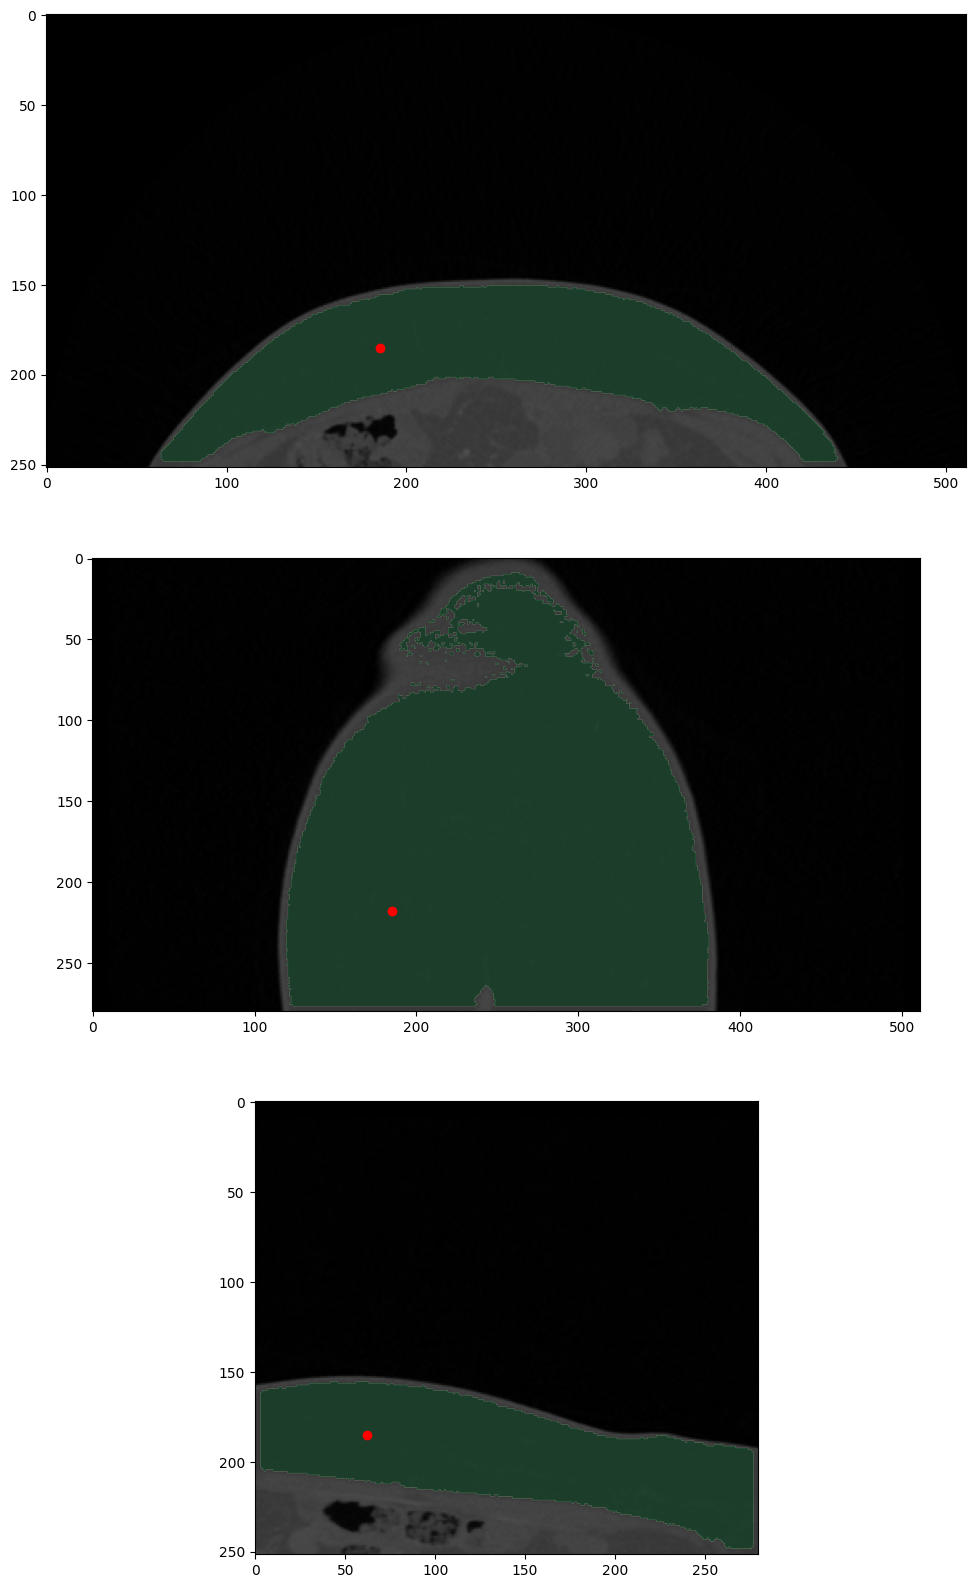

In [126]:
def remove_small_objects_windowed(mask, window_size=3, min_size=[1500, 600, 600]):
    k = window_size
    mask = mask.astype(bool)
    for element in range(3):
        slicing_array = [slice(None), slice(None), slice(None)]
        for i in range(0, mask.shape[element], k):
            for j in range(0, k, k // 2):
                slicing_array[element] = slice(i, i + k)
                # todo: replace remove_small_objects with a function that keeps the labels
                mask[*slicing_array] = remove_small_objects(mask[*slicing_array], min_size=min_size[element])

    return mask


def fat_region_growing(sitk_image, seed, lower=-150, upper=-50):
    return sitk.GetArrayFromImage(sitk.ConnectedThreshold(sitk_image, seedList=[seed[::-1]], lower=lower, upper=upper))


def get_larger_than_fat_area(sitk_image, seed):
    mask = fat_region_growing(sitk_image, seed)

    mask = gaussian_filter(mask, 0.1).astype(np.uint8)

    mask = binary_opening(mask, iterations=2).astype(np.uint8)
    mask = binary_erosion(mask, iterations=1)
    mask = remove_small_objects_windowed(mask, window_size=3, min_size=[2500, 1000, 1000])
    mask = binary_dilation(mask, iterations=5)
    mask = binary_erosion(mask, iterations=1)

    return mask.astype(bool)


def get_fat_and_organ_area(sitk_image, seed):
    mask = fat_region_growing(sitk_image, seed, lower=-160, upper=-40)
    mask = binary_fill_holes(mask)

    return mask.astype(bool)


def get_fat_area(sitk_image, seed):
    fat_dilated = get_larger_than_fat_area(sitk_image, seed)
    fat_and_organ = get_fat_and_organ_area(sitk_image, seed)
    mask = fat_and_organ * fat_dilated

    mask = binary_opening(mask, iterations=1).astype(np.uint8)
    mask = gaussian_filter(mask, 0.1).astype(np.uint8)
    mask = remove_small_objects_windowed(mask, window_size=3, min_size=[2500, 1000, 1000])
    mask = 1 - remove_small_objects_windowed(1 - mask, window_size=3, min_size=[2500, 1000, 1000])

    mask = binary_closing(mask, iterations=2)
    mask = binary_opening(mask, iterations=2)
    mask = gaussian_filter(mask, 0.1).astype(np.uint8)
    mask = binary_fill_holes(mask)

    return mask.astype(bool)


def crop_image(_sitk_image, seed, line_points):
    seed = list(seed)
    seed[0] -= line_points["z_below_fat"]

    sitk_image = _sitk_image
    img = sitk.GetArrayFromImage(sitk_image)
    img = img[line_points["z_below_fat"]:line_points["z_above_fat"], :line_points["y_below_fat"], :]

    img = gaussian_filter(img, 0.1)

    sitk_image = sitk.GetImageFromArray(img)
    sitk_image.SetSpacing(_sitk_image.GetSpacing())

    return sitk_image, seed


sitk_image, seed = crop_image(_sitk_image, _seed, line_points)
img = sitk.GetArrayFromImage(sitk_image)

mask = get_fat_area(sitk_image, seed)
mask = binary_erosion(mask, iterations=1)

show_slice(img, mask, (vein_slide, seed[1], seed[2]))

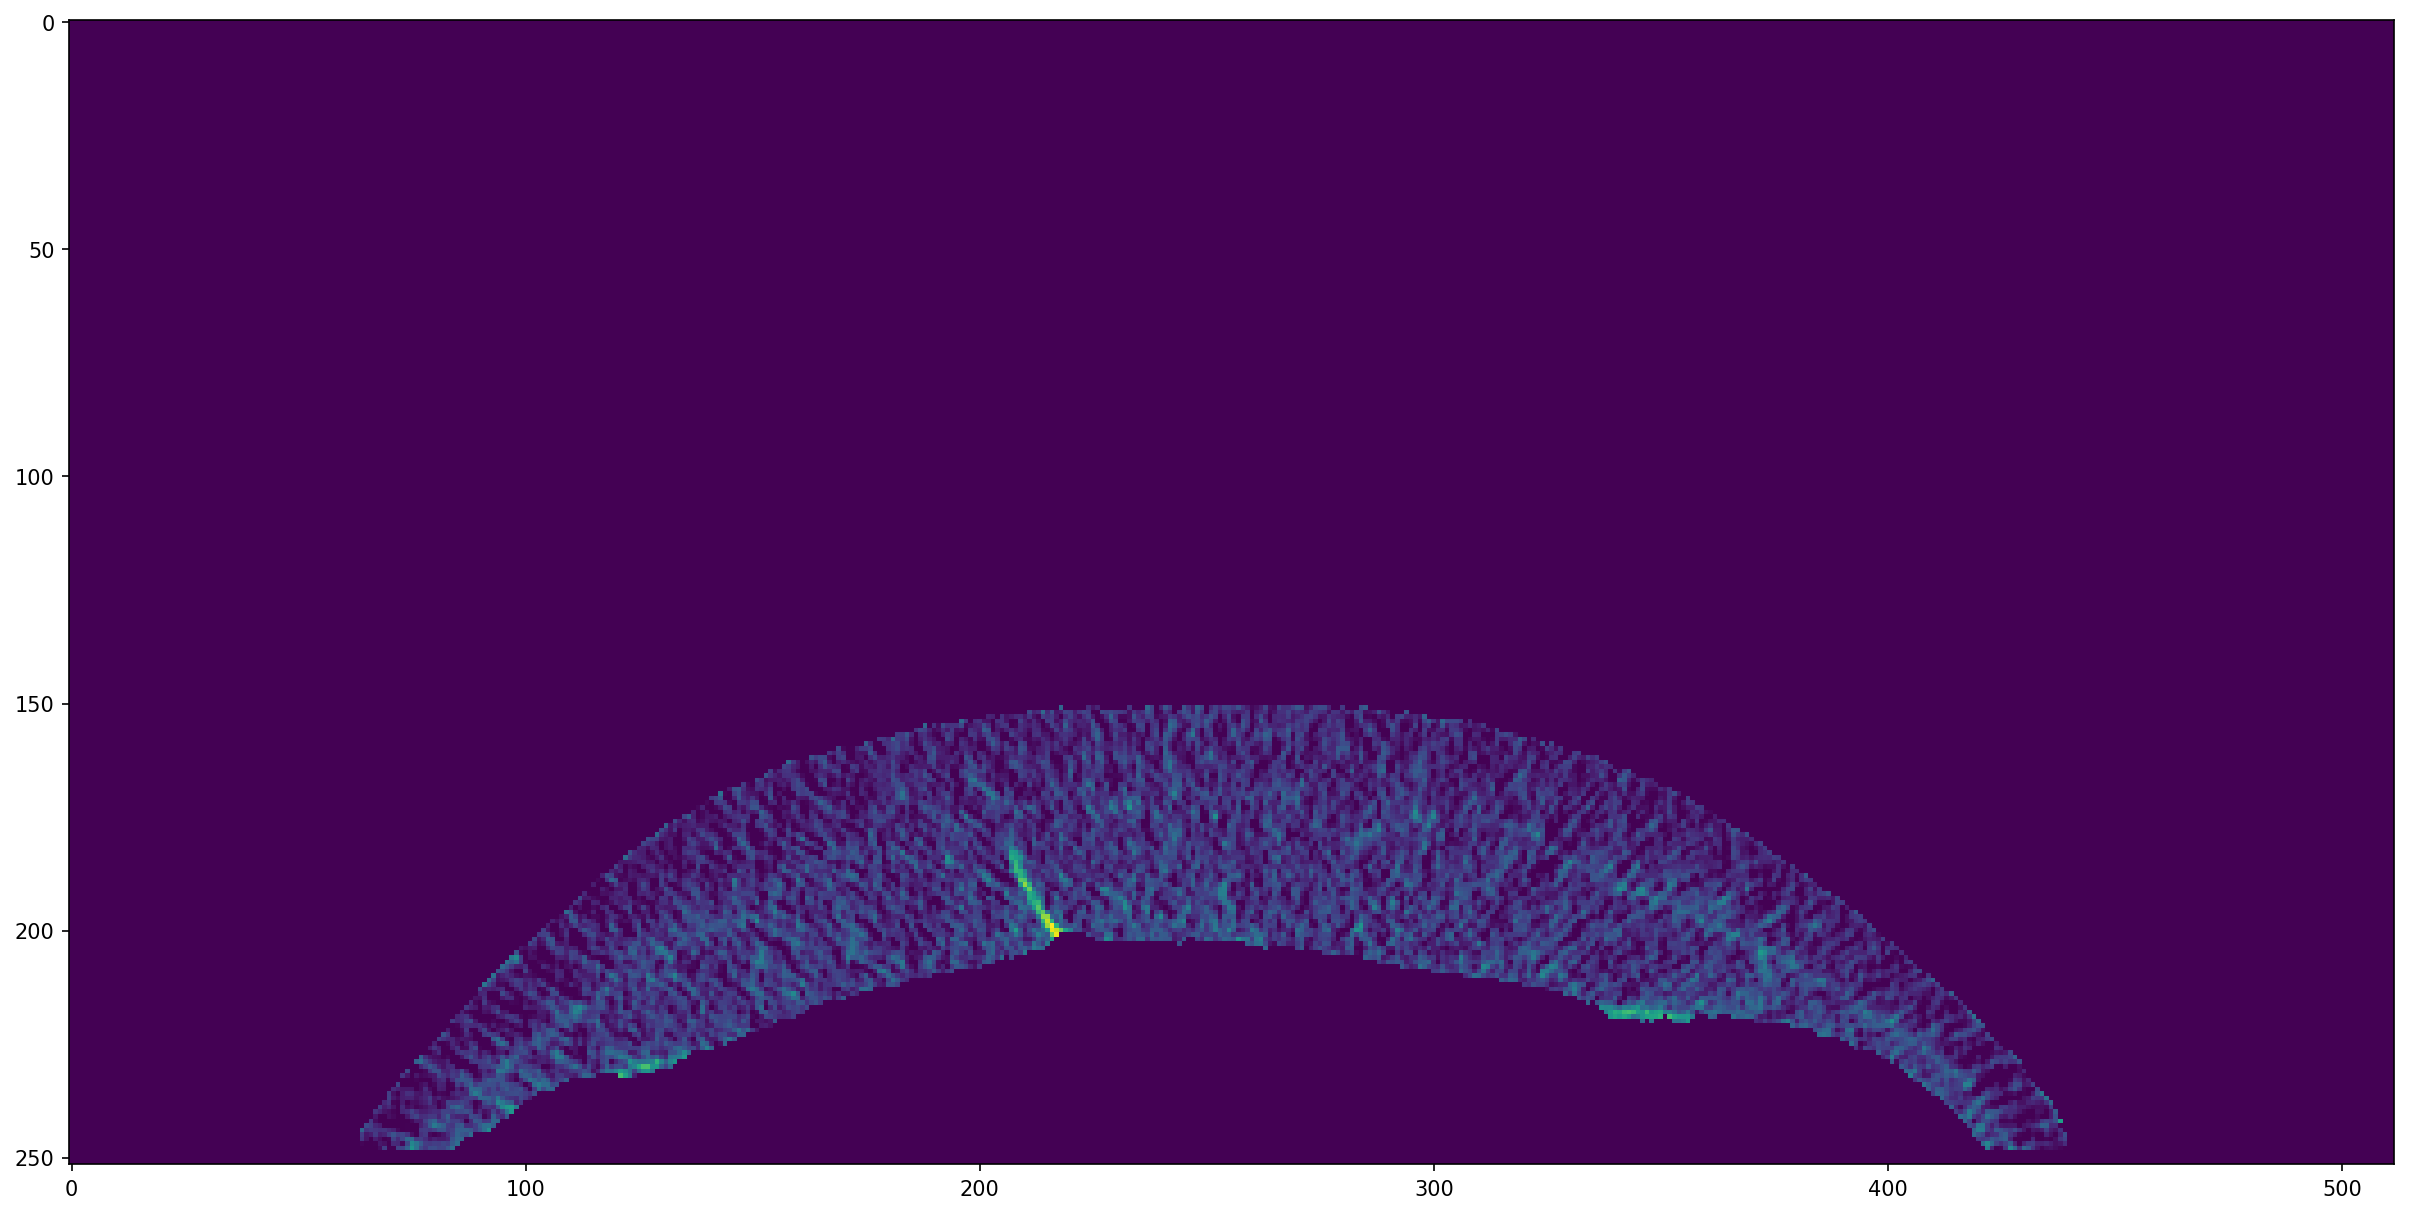

In [136]:
img_balanced = (img + 10000) * mask - 10000

max_value, min_value = np.percentile(img_balanced[mask.astype(bool)], [99.9, 10])
img_balanced = np.clip(img_balanced, min_value, max_value)

img_balanced = (img_balanced - min_value) / (max_value - min_value)

#todo: use a larger, dynamic window size instead of +-3
roi_slide = 3
img_balanced = img_balanced[vein_slide - roi_slide:vein_slide + roi_slide]
img_balanced = gaussian_filter(img_balanced, 0.1)

plt.figure(figsize=(20, 15), dpi=150)
plt.imshow(img_balanced[roi_slide])

In [128]:
# Apply the Frangi filter with adjusted parameters
frangi_slice = frangi(
    img_balanced,
    # scale_range=(1, 2),  # More sensitive to different scales
    scale_step=0.2,  # More fine-grained scale steps
    beta=1.2,  # More sensitive to line-like structures
    gamma=4,  # Less background suppression for more sensitivity
    black_ridges=False  # Assuming bright ridges on dark background
)

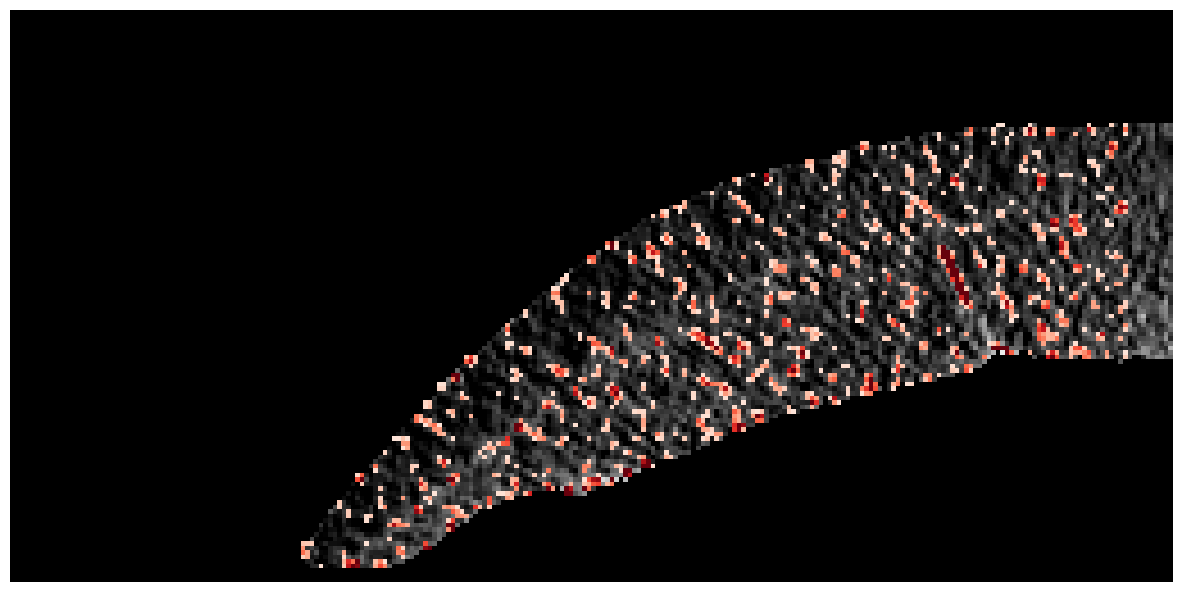

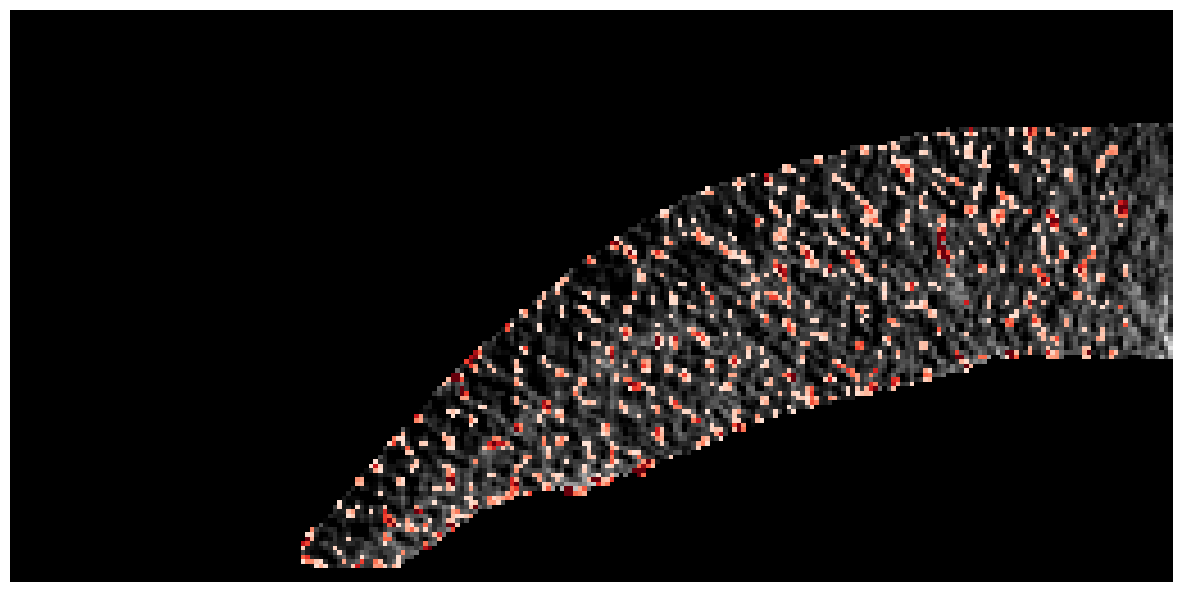

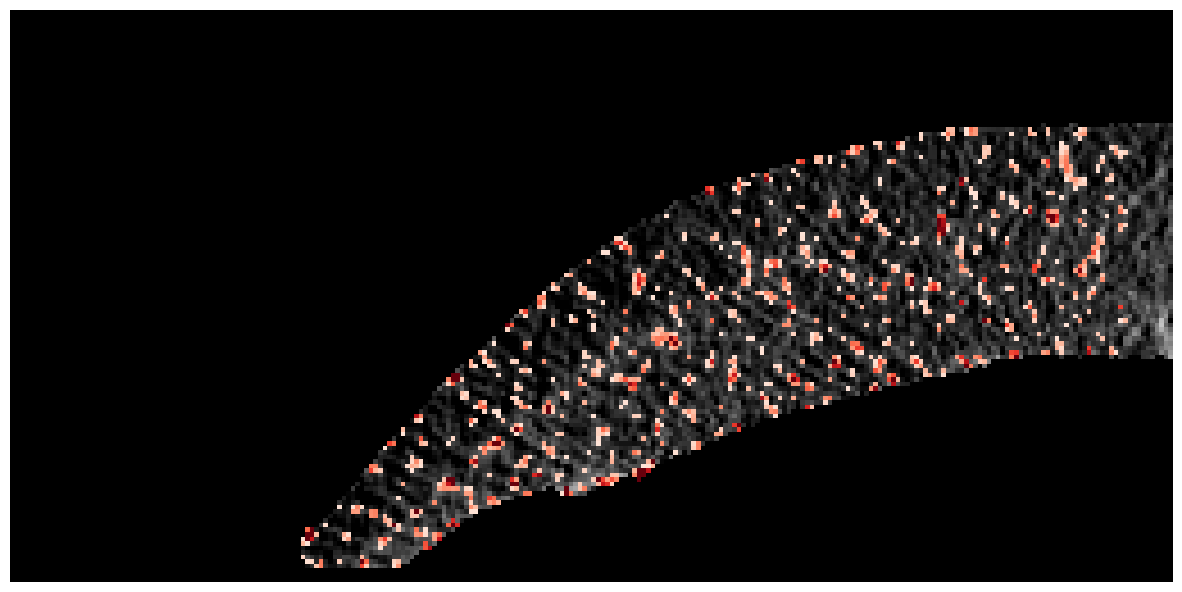

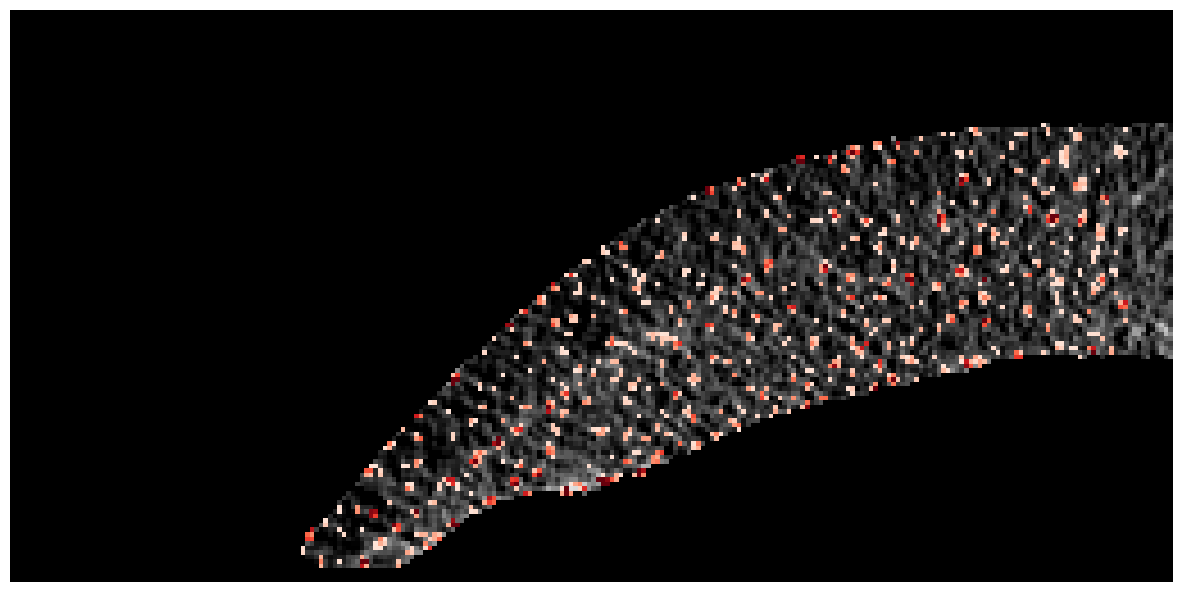

In [129]:
normlized_frangi = frangi_slice.copy()
normlized_frangi = np.clip(normlized_frangi,
                           *np.percentile(normlized_frangi[normlized_frangi > 0], [5, 99.8]))
normlized_frangi /= np.max(normlized_frangi)
normlized_frangi[normlized_frangi < 0.1] = 0
normlized_frangi[:, :, normlized_frangi.shape[2] // 2 - 10:normlized_frangi.shape[2] // 2 + 10] = 0

for i in np.arange(-1, 2 + 1, 1):
    plt.figure(figsize=(15, 10), dpi=100)
    temp = [roi_slide + i, slice(len(img[0]) // 2, len(img[0])), slice(0, len(img[0][0]) // 2)]
    plt.imshow(img_balanced[*temp], cmap="gray")
    plt.imshow(normlized_frangi[*temp], cmap='Reds', alpha=(normlized_frangi[*temp] > 0).astype(float))
    plt.axis('off')
    plt.show()

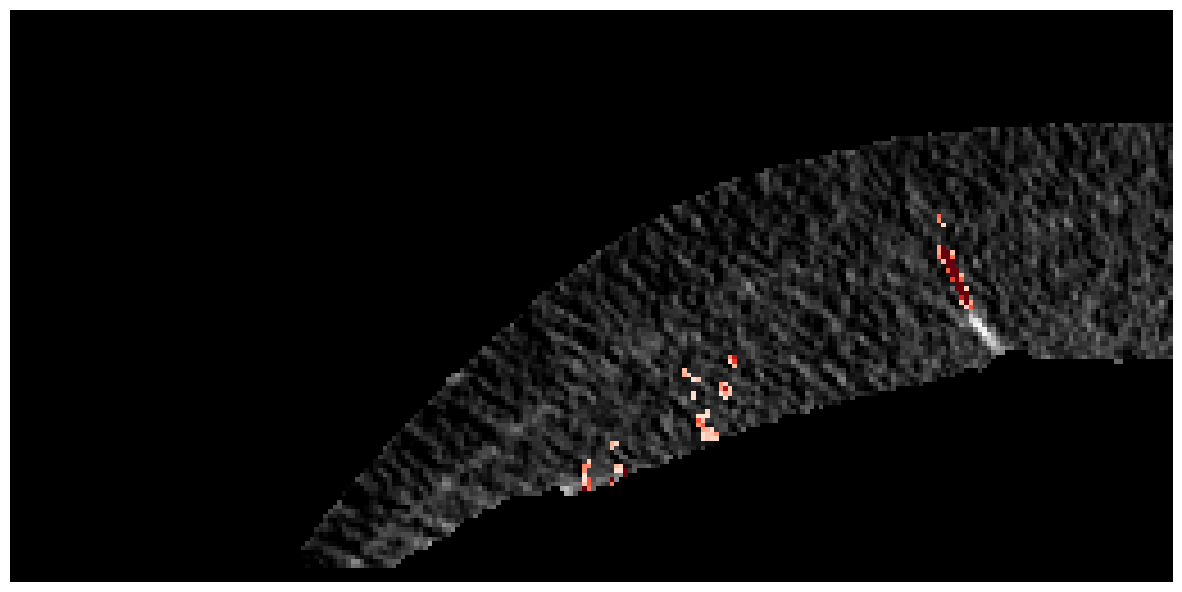

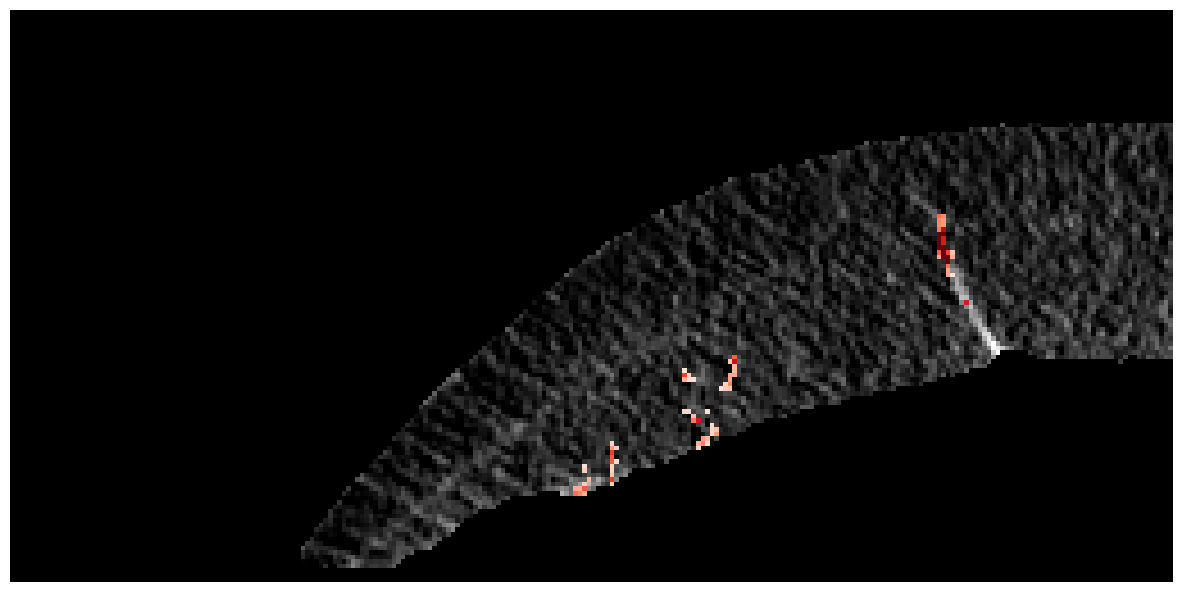

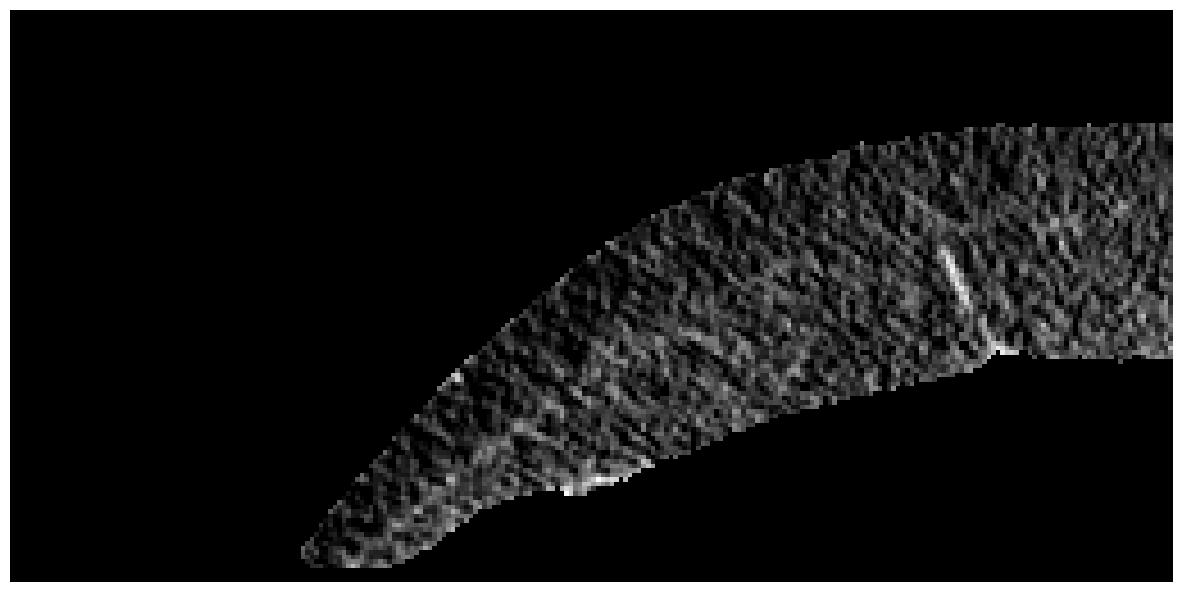

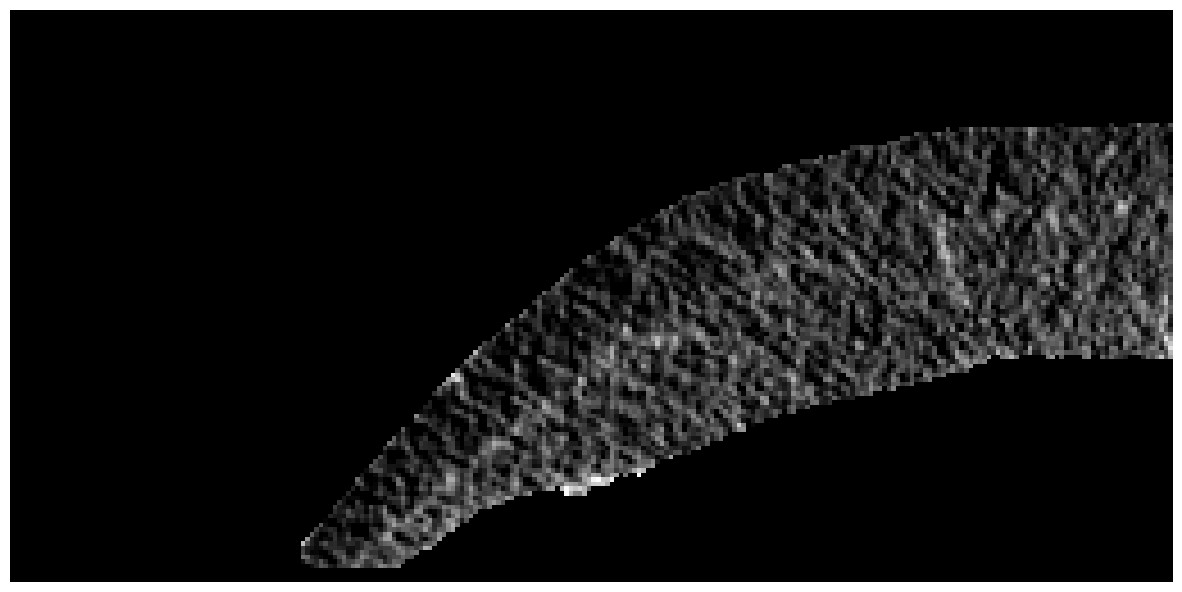

In [137]:
def remove_small_objects_windowed_via_counting(_mask, window_size=3, min_size=[1500, 600, 600], min_count=4):
    mask = _mask > 0
    count_img = mask.copy().astype(int)
    k = window_size
    for element in range(3):
        slicing_array = [slice(None), slice(None), slice(None)]
        for i in range(0, mask.shape[element], k):
            for j in range(0, k, k // 2):
                slicing_array[element] = slice(i, i + k)
                # todo: replace remove_small_objects with a function that keeps the labels
                count_img[*slicing_array] += remove_small_objects(mask[*slicing_array], min_size=min_size[element])

    count_img[count_img < min_count] = 0
    return (count_img > 0) * _mask


filtered_frangi = normlized_frangi.copy()

filtered_frangi = remove_small_objects_windowed_via_counting(
    filtered_frangi, window_size=4, min_size=[50, 8, 25], min_count=3)

filtered_frangi = grey_closing(filtered_frangi, size=(2, 2, 2))
filtered_frangi = remove_small_objects_windowed_via_counting(
    filtered_frangi, window_size=4, min_size=[65, 10, 30], min_count=5)

filtered_frangi = remove_small_objects_windowed_via_counting(
    filtered_frangi, window_size=4, min_size=[70, 12, 40], min_count=5)

temp = grey_dilation(filtered_frangi, size=(2, 2, 2))
temp = remove_small_objects_windowed(temp, window_size=4, min_size=[250, 20, 75])
filtered_frangi *= temp

for i in np.arange(-1, 2 + 1, 1):
    plt.figure(figsize=(15, 10), dpi=100)
    temp = [roi_slide + i, slice(len(img[0]) // 2, len(img[0])), slice(0, len(img[0][0]) // 2)]
    plt.imshow(img_balanced[*temp], cmap="gray")
    plt.imshow(filtered_frangi[*temp], cmap='Reds', alpha=(filtered_frangi[*temp] > 0).astype(float))
    plt.axis('off')
    plt.show()